# Phase 5 — Model Training for FD003
**Notebook:** `10_Model_Training_FD003.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

This notebook trains the **same four algorithms with the same protocol as FD001** (`04_Model_Training_FD001`), using the FD003 preprocessing and features frozen in `09_Preprocessing_FD003` and `09b_Feature_Engineering_FD003`.

| # | Model | Input | Tuning |
|---|---|---|---|
| 1 | Linear Regression | tabular features | none (baseline) |
| 2 | Random Forest | tabular features | 4 configs (see Cell 4) |
| 3 | XGBoost | tabular features | 6 configs + early stopping |
| 4 | LSTM | sequence windows from `feature_config.json` | 4 architectures + early stopping |

### Validation protocol (identical to FD001)
```
training engines ──┬── 80% TRAIN engines ──┬── 80% "fit" engines   → fit candidate configs
                   │                       └── 20% "tune" engines  → choose hyperparameters
                   │                         then: re-train chosen config on all TRAIN engines
                   └── 20% VALIDATION engines → final comparison only (cut points from Phase 3)
Official NASA test set → NOT used here (Phase 6, once, after selection)
```
Primary metric everywhere: **RMSE on test-like points with true RUL ≤ cap**, plus MAE, NASA score, bias (+ = late = dangerous) and RMSE over all points.

**The `src/` code is reused unchanged** (`model_training.py` from FD001), so all four datasets are trained by exactly the same functions.

⚙️ **Runtime:** **Runtime → Change runtime type → T4 GPU** (XGBoost + LSTM use it; Random Forest uses the 2 CPU cores). Expect roughly **15–30 minutes** on Colab, mostly Random Forest tuning. Every model is saved to Drive as soon as it finishes.

## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

FD, SEED = "FD003", 42
MODEL_DIR  = PROJECT_DIR / "models" / FD
PREP_DIR   = MODEL_DIR / "preprocessing"
PROC_DIR   = PROJECT_DIR / "data" / "processed" / FD
FIG_DIR    = PROJECT_DIR / "reports" / "figures" / FD
RESULT_DIR = PROJECT_DIR / "reports" / "model_results" / FD
for p in (FIG_DIR, RESULT_DIR):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
sns.set_theme(style="whitegrid")

import torch, xgboost, sklearn
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | xgboost {xgboost.__version__} | scikit-learn {sklearn.__version__}")
print("Device:", DEVICE, "| CPU cores:", os.cpu_count())
assert (PREP_DIR / "preprocessing_config.json").exists(), "Preprocessing missing → run 09_Preprocessing_FD003 first"
assert (MODEL_DIR / "feature_config.json").exists(), "feature_config.json missing → run 09b_Feature_Engineering_FD003 first"
assert (PROJECT_DIR / "src" / "model_training.py").exists(), "src/model_training.py missing → run 04_Model_Training_FD001 first"
print("✅ Phase 3 + Phase 4 artifacts found")

torch 2.15.0+cpu | xgboost 3.4.1 | scikit-learn 1.7.0
Device: cpu | CPU cores: 16
✅ Phase 3 + Phase 4 artifacts found


## Cell 2 — Load frozen artifacts and build every model input
Nothing is re-fitted: the preprocessor (single-regime or per-regime), feature list, cap, window and LSTM recipe all come from Drive. The LSTM recipe can include causal rolling means (FD002/FD004); the code reads that from `feature_config.json`.

In [2]:
# Cell 2 — Load artifacts + build datasets
import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev
import src.feature_engineering as fe, src.model_training as mt, src.regime_preprocessing as rp
for m in (dl, pp, ev, fe, mt, rp):
    importlib.reload(m)
mt.set_seed(SEED)

feat_cfg  = json.loads((MODEL_DIR / "feature_config.json").read_text())
pipe_meta = json.loads((PREP_DIR / "pipeline_metadata.json").read_text())
split     = json.loads((PROC_DIR / "split.json").read_text())
val_cuts  = pd.read_csv(PROC_DIR / "val_cut_points.csv")
prep      = rp.load_preprocessor(PREP_DIR)

CAP       = pipe_meta["rul_cap"]
MIN_HIST  = pipe_meta.get("min_history", 30)
B         = feat_cfg["base_features"]
WINDOW    = feat_cfg["tabular"]["window"]
INC_CYC   = feat_cfg["tabular"]["include_cycle"]
NAMES     = feat_cfg["tabular"]["feature_order"]
SEQ_LEN   = feat_cfg["lstm"]["seq_len"]
LSTM_FEATS = feat_cfg["lstm"]["features"]
LSTM_RW   = feat_cfg["lstm"].get("rolling_window")
assert NAMES == fe.tabular_feature_names(B, WINDOW, INC_CYC) and B == prep.feature_cols

d = dl.load_dataset(FD, RAW_DIR)
capped   = pp.add_train_rul(d["train"], cap=CAP)          # training target
uncapped = pp.add_train_rul(d["train"])                   # evaluation target
train_ids, val_ids = split["train_engine_ids"], split["val_engine_ids"]
fit_ids, tune_ids = pp.split_engines(capped[capped.engine_id.isin(train_ids)], val_fraction=0.2, seed=SEED)
tune_cuts = pp.make_eval_cut_points(uncapped[uncapped.engine_id.isin(tune_ids)], n_cuts=10,
                                    min_history=MIN_HIST, seed=SEED)
assert not set(fit_ids) & set(tune_ids) and set(fit_ids) | set(tune_ids) == set(train_ids)
assert not set(train_ids) & set(val_ids)

all_s = prep.transform(capped)
feat_all, _ = fe.build_tabular(all_s, B, WINDOW, INC_CYC)
sel = lambda ids: feat_all[feat_all.engine_id.isin(ids)]
X_fit, y_fit   = sel(fit_ids)[NAMES],   sel(fit_ids)["RUL"]
X_tr80, y_tr80 = sel(train_ids)[NAMES], sel(train_ids)["RUL"]
X_tune_rows, y_tune_rows = sel(tune_ids)[NAMES], sel(tune_ids)["RUL"]
X_tune_pts = fe.rows_at(feat_all, tune_cuts)[NAMES]; y_tune_true = tune_cuts["true_rul"].values
X_val_pts  = fe.rows_at(feat_all, val_cuts)[NAMES];  y_val_true  = val_cuts["true_rul"].values

seq_src = fe.add_rolling_features(all_s, B, LSTM_RW) if LSTM_RW else all_s
seq = lambda ids: fe.make_sequences(seq_src[seq_src.engine_id.isin(ids)], LSTM_FEATS, SEQ_LEN)
S_fit, s_fit, _   = seq(fit_ids)
S_tune, s_tune, _ = seq(tune_ids)
S_tr80, s_tr80, _ = seq(train_ids)
S_tune_pts = fe.sequences_at(seq_src, LSTM_FEATS, SEQ_LEN, tune_cuts)
S_val_pts  = fe.sequences_at(seq_src, LSTM_FEATS, SEQ_LEN, val_cuts)
N_VAL = len(val_cuts)

print(f"{type(prep).__name__} | cap {CAP} | {len(NAMES)} tabular features (window {WINDOW}) | "
      f"LSTM {SEQ_LEN}×{len(LSTM_FEATS)}" + (f" (incl. rolling means {LSTM_RW})" if LSTM_RW else ""))
print(f"Engines: fit {len(fit_ids)} | tune {len(tune_ids)} | train {len(train_ids)} | validation {len(val_ids)}")
print(f"Tabular rows: fit {len(X_fit)} | train {len(X_tr80)} | tune points {len(X_tune_pts)} | val points {N_VAL}")
print(f"LSTM windows: fit {S_fit.shape} | tune {S_tune.shape} | train {S_tr80.shape} | val points {S_val_pts.shape}")
results, val_preds = {}, {"engine_id": val_cuts.engine_id, "cut_cycle": val_cuts.cut_cycle, "true_rul": y_val_true}

CMAPSSPreprocessor | cap 125 | 57 tabular features (window 30) | LSTM 30×28 (incl. rolling means 30)
Engines: fit 64 | tune 16 | train 80 | validation 20
Tabular rows: fit 15676 | train 19827 | tune points 160 | val points 200
LSTM windows: fit (13820, 30, 28) | tune (3687, 30, 28) | train (17507, 30, 28) | val points (200, 30, 28)


---
## Cell 3 — Model 1: Linear Regression (baseline)
A weighted sum of the tabular features. No hyperparameters, so it's fitted directly on all training engines. Every other model must beat it. Predictions are clipped at 0 (RUL can't be negative).

In [3]:
# Cell 3 — Linear Regression
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
t0 = time.perf_counter(); lr.fit(X_tr80, y_tr80); lr_train_s = time.perf_counter() - t0
pred, lr_inf_s = mt.time_inference(lambda: np.clip(lr.predict(X_val_pts), 0, None))
val_preds["Linear Regression"] = pred
results["Linear Regression"] = {**mt.point_metrics(y_val_true, pred, CAP),
                                "train_s": lr_train_s, "tuning_s": 0.0, "infer_ms": lr_inf_s * 1000}
size = mt.save_model_bundle(MODEL_DIR / "linear_regression", lr, "sklearn", {
    "dataset": FD, "model": "Linear Regression", "input": "tabular", "feature_order": NAMES,
    "rul_cap": CAP, "hyperparameters": {}, "train_engines": len(train_ids),
    "train_time_s": lr_train_s, "validation_metrics": results["Linear Regression"]})
r = results["Linear Regression"]
print(f"Validation ({N_VAL} pts): RMSE≤{CAP} {r['RMSE_le_cap']:.2f} | MAE {r['MAE_le_cap']:.2f} | "
      f"bias {r['bias_le_cap']:+.1f} | RMSE all {r['RMSE_all']:.2f} | saved {size:.2f} MB")

Validation (200 pts): RMSE≤125 19.37 | MAE 15.95 | bias +7.2 | RMSE all 53.23 | saved 0.00 MB


## Cell 4 — Model 2: Random Forest (tuned)
**Grid (4 configs, 150 trees each):** `min_samples_leaf` ∈ {3, 8} × `max_features` ∈ {0.33, 0.6}, with unlimited depth.

**Difference from FD001:** FD001 also tried `max_depth = 12` (8 configs), and unlimited depth won there. This dataset has 2–3× more rows, so on Colab's 2 CPU cores the 8-config grid would take 30+ minutes. We keep the four configs that cover the useful region. A progress line prints after every fit.

In [4]:
# Cell 4 — Random Forest
from sklearn.ensemble import RandomForestRegressor
from itertools import product
rf_grid = [{"min_samples_leaf": l, "max_features": f} for l, f in product([3, 8], [0.33, 0.6])]
make_rf = lambda **p: RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=SEED, **p)

t0 = time.perf_counter()
rf_tuning, rf_best, _ = mt.tune_tabular(make_rf, rf_grid, X_fit, y_fit, X_tune_pts, y_tune_true, CAP)
rf_tuning_s = time.perf_counter() - t0
rf_tuning.to_csv(RESULT_DIR / "rf_tuning.csv", index=False)
display(rf_tuning.round(3)); print("Best RF config:", rf_best)

rf = make_rf(**rf_best)
t0 = time.perf_counter(); rf.fit(X_tr80, y_tr80); rf_train_s = time.perf_counter() - t0
pred, rf_inf_s = mt.time_inference(lambda: np.clip(rf.predict(X_val_pts), 0, None))
val_preds["Random Forest"] = pred
results["Random Forest"] = {**mt.point_metrics(y_val_true, pred, CAP),
                            "train_s": rf_train_s, "tuning_s": rf_tuning_s, "infer_ms": rf_inf_s * 1000}
rf_imp = pd.Series(rf.feature_importances_, index=NAMES).sort_values(ascending=False)
rf_imp.to_csv(RESULT_DIR / "rf_feature_importance.csv")
size = mt.save_model_bundle(MODEL_DIR / "random_forest", rf, "sklearn", {
    "dataset": FD, "model": "Random Forest", "input": "tabular", "feature_order": NAMES, "rul_cap": CAP,
    "hyperparameters": {"n_estimators": 150, **rf_best}, "train_engines": len(train_ids),
    "train_time_s": rf_train_s, "tuning_time_s": rf_tuning_s, "validation_metrics": results["Random Forest"]})
r = results["Random Forest"]
print(f"Validation ({N_VAL} pts): RMSE≤{CAP} {r['RMSE_le_cap']:.2f} | MAE {r['MAE_le_cap']:.2f} | "
      f"bias {r['bias_le_cap']:+.1f} | RMSE all {r['RMSE_all']:.2f} | saved {size:.1f} MB")

  [1/4] {'min_samples_leaf': 3, 'max_features': 0.33} {} -> tune RMSE<=cap 15.02 (3.5s)


  [2/4] {'min_samples_leaf': 3, 'max_features': 0.6} {} -> tune RMSE<=cap 15.26 (6.1s)


  [3/4] {'min_samples_leaf': 8, 'max_features': 0.33} {} -> tune RMSE<=cap 15.04 (3.1s)


  [4/4] {'min_samples_leaf': 8, 'max_features': 0.6} {} -> tune RMSE<=cap 15.31 (6.5s)


,min_samples_leaf,max_features,tune_RMSE_le_cap,tune_NASA_le_cap,fit_s
0,3,0.33,15.024,375.089,3.515
1,8,0.33,15.036,369.548,3.083
2,3,0.60,15.263,392.741,6.142
3,8,0.60,15.309,405.289,6.460


Best RF config: {'min_samples_leaf': 3, 'max_features': 0.33}


Validation (200 pts): RMSE≤125 12.52 | MAE 9.35 | bias +6.5 | RMSE all 49.68 | saved 11.7 MB


## Cell 5 — Model 3: XGBoost (tuned, early stopping)
Same as FD001: `max_depth` ∈ {3, 5, 7} × `learning_rate` ∈ {0.03, 0.1}; up to 2000 trees with early stopping (100 rounds) on the tune engines. The best tree count is reused when refitting on all training engines.

In [5]:
# Cell 5 — XGBoost
from xgboost import XGBRegressor
xgb_grid = [{"max_depth": dp, "learning_rate": lr_} for dp, lr_ in product([3, 5, 7], [0.03, 0.1])]
xgb_common = dict(subsample=0.8, colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                  device=DEVICE, random_state=SEED, n_jobs=-1)
make_xgb = lambda **p: XGBRegressor(n_estimators=2000, early_stopping_rounds=100, eval_metric="rmse",
                                    **xgb_common, **p)
t0 = time.perf_counter()
xgb_tuning, xgb_best, _ = mt.tune_tabular(make_xgb, xgb_grid, X_fit, y_fit, X_tune_pts, y_tune_true, CAP,
                                          fit_kwargs_fn=lambda m: {"eval_set": [(X_tune_rows, y_tune_rows)],
                                                                   "verbose": False})
xgb_tuning_s = time.perf_counter() - t0
xgb_tuning.to_csv(RESULT_DIR / "xgb_tuning.csv", index=False)
display(xgb_tuning.round(3))
n_trees = xgb_best.pop("best_iteration") + 1
xgb_params = {**xgb_best, "n_estimators": n_trees}
print("Best XGBoost config:", xgb_params)

xgb = XGBRegressor(**xgb_common, **xgb_params)
t0 = time.perf_counter(); xgb.fit(X_tr80, y_tr80, verbose=False); xgb_train_s = time.perf_counter() - t0
pred, xgb_inf_s = mt.time_inference(lambda: np.clip(xgb.predict(X_val_pts), 0, None))
val_preds["XGBoost"] = pred
results["XGBoost"] = {**mt.point_metrics(y_val_true, pred, CAP),
                      "train_s": xgb_train_s, "tuning_s": xgb_tuning_s, "infer_ms": xgb_inf_s * 1000}
xgb_imp = pd.Series(xgb.get_booster().get_score(importance_type="gain")).reindex(NAMES).fillna(0)
xgb_imp = (xgb_imp / xgb_imp.sum()).sort_values(ascending=False)
xgb_imp.to_csv(RESULT_DIR / "xgb_feature_importance.csv")
size = mt.save_model_bundle(MODEL_DIR / "xgboost", xgb, "xgboost", {
    "dataset": FD, "model": "XGBoost", "input": "tabular", "feature_order": NAMES, "rul_cap": CAP,
    "hyperparameters": {**{k: v for k, v in xgb_common.items() if k not in ("device", "n_jobs")}, **xgb_params},
    "train_engines": len(train_ids), "train_time_s": xgb_train_s, "tuning_time_s": xgb_tuning_s,
    "validation_metrics": results["XGBoost"]})
r = results["XGBoost"]
print(f"Validation ({N_VAL} pts): RMSE≤{CAP} {r['RMSE_le_cap']:.2f} | MAE {r['MAE_le_cap']:.2f} | "
      f"bias {r['bias_le_cap']:+.1f} | RMSE all {r['RMSE_all']:.2f} | saved {size:.2f} MB")

  [1/6] {'max_depth': 3, 'learning_rate': 0.03} {'best_iteration': 666} -> tune RMSE<=cap 15.12 (1.2s)


  [2/6] {'max_depth': 3, 'learning_rate': 0.1} {'best_iteration': 226} -> tune RMSE<=cap 15.83 (0.6s)


  [3/6] {'max_depth': 5, 'learning_rate': 0.03} {'best_iteration': 326} -> tune RMSE<=cap 15.14 (1.4s)


  [4/6] {'max_depth': 5, 'learning_rate': 0.1} {'best_iteration': 88} -> tune RMSE<=cap 15.38 (0.6s)


  [5/6] {'max_depth': 7, 'learning_rate': 0.03} {'best_iteration': 207} -> tune RMSE<=cap 15.36 (1.6s)


  [6/6] {'max_depth': 7, 'learning_rate': 0.1} {'best_iteration': 61} -> tune RMSE<=cap 15.69 (0.8s)


,max_depth,learning_rate,best_iteration,tune_RMSE_le_cap,tune_NASA_le_cap,fit_s
0,3,0.03,666,15.119,407.744,1.172
1,5,0.03,326,15.135,439.151,1.408
2,7,0.03,207,15.362,390.855,1.584
3,5,0.10,88,15.376,501.140,0.618
4,7,0.10,61,15.695,483.715,0.752
5,3,0.10,226,15.827,544.628,0.616


Best XGBoost config: {'max_depth': 3, 'learning_rate': 0.03, 'n_estimators': 667}


Validation (200 pts): RMSE≤125 12.85 | MAE 8.98 | bias +6.0 | RMSE all 49.67 | saved 0.80 MB


## Cell 6 — Which features do RF and XGBoost rely on?
Importances normalised to sum to 1; Spearman ρ = agreement of the two rankings. The second table groups importance by feature type (current value / rolling mean / std / slope / cycle).

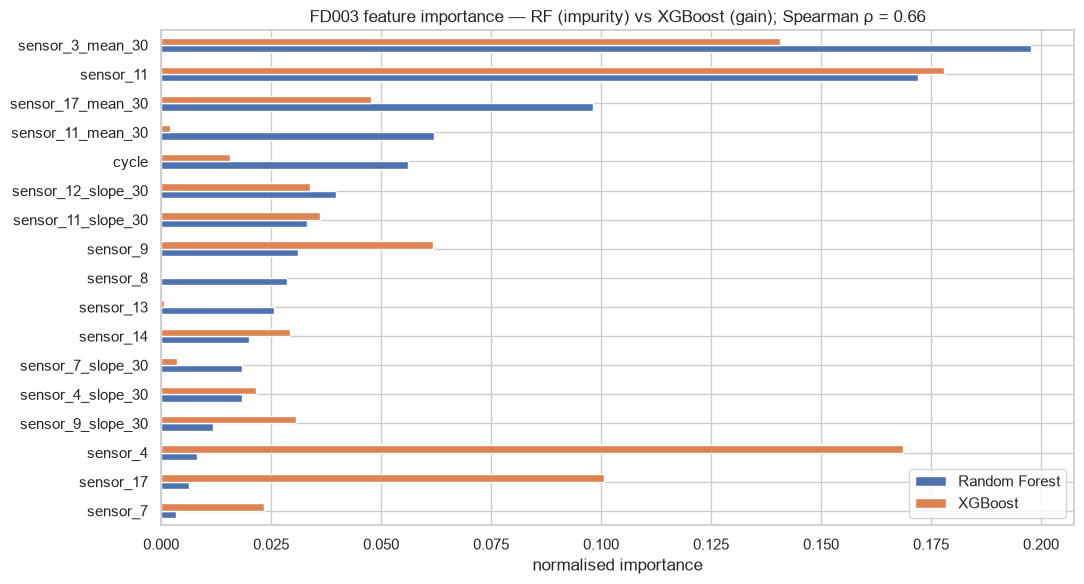

,Random Forest,XGBoost
current value,0.301,0.588
cycle,0.056,0.016
mean,0.436,0.210
slope,0.158,0.168
std,0.050,0.018


In [6]:
# Cell 6 — Feature importance comparison
from scipy.stats import spearmanr
top_feats = list(dict.fromkeys(list(rf_imp.index[:12]) + list(xgb_imp.index[:12])))
imp_df = pd.DataFrame({"Random Forest": rf_imp, "XGBoost": xgb_imp}).loc[top_feats]
rho = spearmanr(rf_imp.reindex(NAMES), xgb_imp.reindex(NAMES)).correlation
fig, ax = plt.subplots(figsize=(11, 6))
imp_df.sort_values("Random Forest").plot.barh(ax=ax)
ax.set(title=f"{FD} feature importance — RF (impurity) vs XGBoost (gain); Spearman ρ = {rho:.2f}",
       xlabel="normalised importance")
fig.tight_layout(); fig.savefig(FIG_DIR / "train_rf_vs_xgb_importance.png", dpi=150, bbox_inches="tight"); plt.show()
kind = lambda n: "cycle" if n == "cycle" else ("slope" if "_slope_" in n else "std" if "_std_" in n
                                                else "mean" if "_mean_" in n else "current value")
display(pd.DataFrame({"Random Forest": rf_imp.groupby(rf_imp.index.map(kind)).sum(),
                      "XGBoost": xgb_imp.groupby(xgb_imp.index.map(kind)).sum()}).round(3))

## Cell 7 — Model 4: LSTM (architecture search + early stopping)
Same training loop as FD001: target scaled to RUL / cap, MSE loss, Adam (lr 0.001), batch 256, gradient clipping, **early stopping** (patience 8) on the tune engines with best-weight restore. Architectures: hidden 64 or 128 × 1 or 2 layers.

The inputs come from `feature_config.json`. For FD002/FD004 that's 21 cycles × (14 sensors + 14 long rolling means), the design you approved in Phase 4.

⏱️ T4 GPU: a few minutes. CPU-only: much longer (it still works).

[1/4] {'hidden': 64, 'layers': 1, 'dropout': 0.0}


    epoch   1  train 0.1115  val 0.0280  (best epoch 1)


    epoch   5  train 0.0091  val 0.0105  (best epoch 5)


    epoch  10  train 0.0051  val 0.0090  (best epoch 8)


    epoch  15  train 0.0039  val 0.0100  (best epoch 8)


    early stop at epoch 16; best epoch 8
  → best epoch 8, tune RMSE 13.37 (9s)
[2/4] {'hidden': 64, 'layers': 2, 'dropout': 0.2}


... (11 outputs left out)

    epoch  10  train 0.0051  val 0.0085  (best epoch 7)


    epoch  15  train 0.0044  val 0.0106  (best epoch 7)
    early stop at epoch 15; best epoch 7
  → best epoch 7, tune RMSE 14.70 (45s)


,hidden,layers,dropout,best_epoch,tune_RMSE_le_cap,tune_NASA_le_cap,fit_s
0,64,1,0.0,8,13.369,283.953,9.133
1,128,1,0.0,8,14.101,342.238,16.647
2,64,2,0.2,7,14.423,369.381,18.335
3,128,2,0.2,7,14.699,433.718,45.389


Best LSTM config: {'hidden': 64, 'layers': 1, 'dropout': 0.0, 'best_epoch': 8}


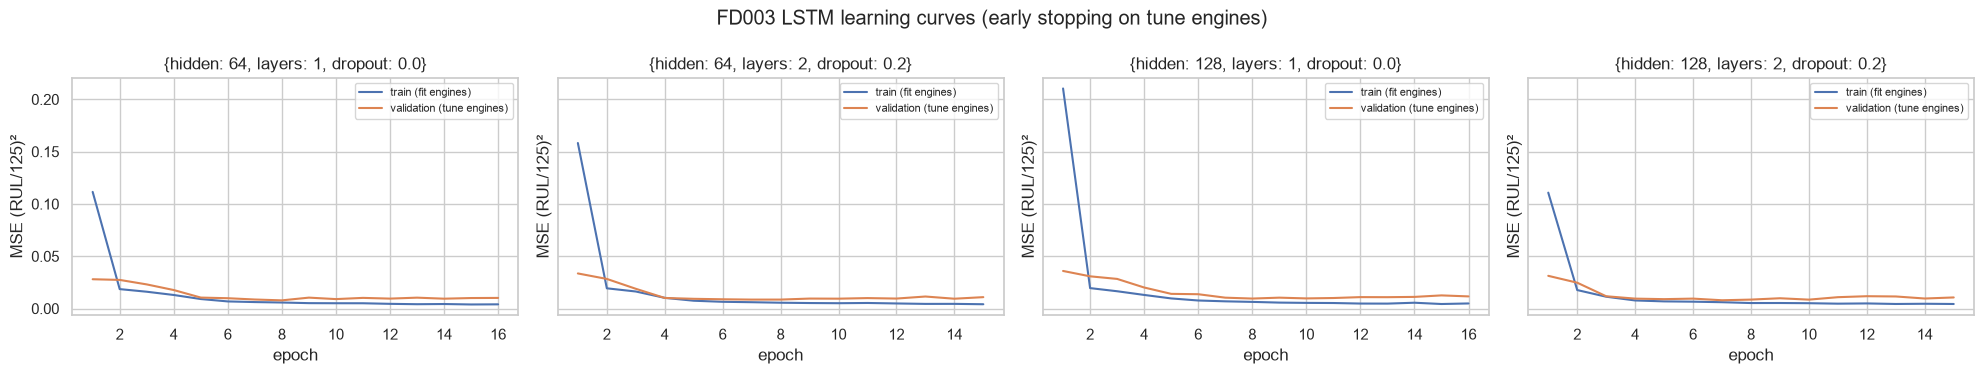

In [7]:
# Cell 7 — LSTM tuning
lstm_grid = [{"hidden": 64, "layers": 1, "dropout": 0.0}, {"hidden": 64, "layers": 2, "dropout": 0.2},
             {"hidden": 128, "layers": 1, "dropout": 0.0}, {"hidden": 128, "layers": 2, "dropout": 0.2}]
LSTM_TRAIN = dict(epochs=60, patience=8, lr=1e-3, batch_size=256, device=DEVICE, seed=SEED)
lstm_rows, histories, best = [], {}, (np.inf, None, None)
t0 = time.perf_counter()
for i, cfg in enumerate(lstm_grid, 1):
    print(f"[{i}/{len(lstm_grid)}] {cfg}")
    t1 = time.perf_counter()
    net, hist, best_epoch = mt.train_lstm(cfg, S_fit, s_fit, CAP, X_val=S_tune, y_val=s_tune, **LSTM_TRAIN)
    m = mt.point_metrics(y_tune_true, mt.lstm_predict(net, S_tune_pts, CAP, DEVICE), CAP)
    histories[str(cfg)] = hist
    lstm_rows.append({**cfg, "best_epoch": best_epoch, "tune_RMSE_le_cap": m["RMSE_le_cap"],
                      "tune_NASA_le_cap": m["NASA_le_cap"], "fit_s": time.perf_counter() - t1})
    print(f"  → best epoch {best_epoch}, tune RMSE {m['RMSE_le_cap']:.2f} ({lstm_rows[-1]['fit_s']:.0f}s)")
    if m["RMSE_le_cap"] < best[0]:
        best = (m["RMSE_le_cap"], {**cfg, "best_epoch": best_epoch}, net)
lstm_tuning_s = time.perf_counter() - t0
lstm_tuning = pd.DataFrame(lstm_rows).sort_values("tune_RMSE_le_cap").reset_index(drop=True)
lstm_tuning.to_csv(RESULT_DIR / "lstm_tuning.csv", index=False)
display(lstm_tuning.round(3))
lstm_best = best[1]; print("Best LSTM config:", lstm_best)
(MODEL_DIR / "lstm").mkdir(parents=True, exist_ok=True)
torch.save(best[2].state_dict(), MODEL_DIR / "lstm" / "tuning_best_checkpoint.pt")

fig, axes = plt.subplots(1, len(histories), figsize=(5 * len(histories), 3.8), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.epoch, h.train_loss, label="train (fit engines)")
    ax.plot(h.epoch, h.val_loss, label="validation (tune engines)")
    ax.set(title=name.replace("'", ""), xlabel="epoch", ylabel=f"MSE (RUL/{CAP})²"); ax.legend(fontsize=8)
fig.suptitle(f"{FD} LSTM learning curves (early stopping on tune engines)")
fig.tight_layout(); fig.savefig(FIG_DIR / "train_lstm_learning_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## Cell 8 — Re-train the best LSTM on all training engines, save, reload-check

In [8]:
# Cell 8 — Final LSTM
arch = {k: lstm_best[k] for k in ("hidden", "layers", "dropout")}
final_epochs = int(lstm_best["best_epoch"])
t0 = time.perf_counter()
lstm, _, _ = mt.train_lstm(arch, S_tr80, s_tr80, CAP, **{**LSTM_TRAIN, "epochs": final_epochs})
lstm_train_s = time.perf_counter() - t0
pred, lstm_inf_s = mt.time_inference(lambda: mt.lstm_predict(lstm, S_val_pts, CAP, DEVICE))
val_preds["LSTM"] = pred
results["LSTM"] = {**mt.point_metrics(y_val_true, pred, CAP),
                   "train_s": lstm_train_s, "tuning_s": lstm_tuning_s, "infer_ms": lstm_inf_s * 1000}
size = mt.save_model_bundle(MODEL_DIR / "lstm", lstm, "lstm", {
    "dataset": FD, "model": "LSTM", "input": "sequence", "seq_len": SEQ_LEN, "features": LSTM_FEATS,
    "n_features": len(LSTM_FEATS), "rolling_window": LSTM_RW, "architecture": arch, "epochs": final_epochs,
    "training": {k: v for k, v in LSTM_TRAIN.items() if k != "device"}, "target_scaling": f"RUL / {CAP}",
    "rul_cap": CAP, "train_engines": len(train_ids), "train_time_s": lstm_train_s,
    "tuning_time_s": lstm_tuning_s, "validation_metrics": results["LSTM"]})
reloaded, _ = mt.load_lstm(MODEL_DIR / "lstm", DEVICE)
assert np.allclose(mt.lstm_predict(reloaded, S_val_pts, CAP, DEVICE), pred, atol=1e-3)
r = results["LSTM"]
print(f"✅ LSTM saved + reload verified ({size:.2f} MB)")
print(f"Validation ({N_VAL} pts): RMSE≤{CAP} {r['RMSE_le_cap']:.2f} | MAE {r['MAE_le_cap']:.2f} | "
      f"bias {r['bias_le_cap']:+.1f} | RMSE all {r['RMSE_all']:.2f}")

    epoch   1  train 0.0966


    epoch   5  train 0.0069


✅ LSTM saved + reload verified (0.22 MB)
Validation (200 pts): RMSE≤125 13.17 | MAE 9.42 | bias +4.8 | RMSE all 50.64


---
## Cell 9 — Validation comparison of the 4 models

,MAE (≤125),RMSE (≤125),NASA (≤125),Bias (≤125),RMSE (all points),Train time (s),Tuning time (s),"Inference (ms, all val points)"
Model,,,,,,,,
Linear Regression,15.95,19.37,1105.88,7.24,53.23,0.02,0.00,0.50
Random Forest,9.35,12.52,430.82,6.46,49.68,4.65,19.30,28.62
XGBoost,8.98,12.85,588.96,5.98,49.67,0.87,6.19,2.24
LSTM,9.42,13.17,446.48,4.78,50.64,4.55,89.50,1.59


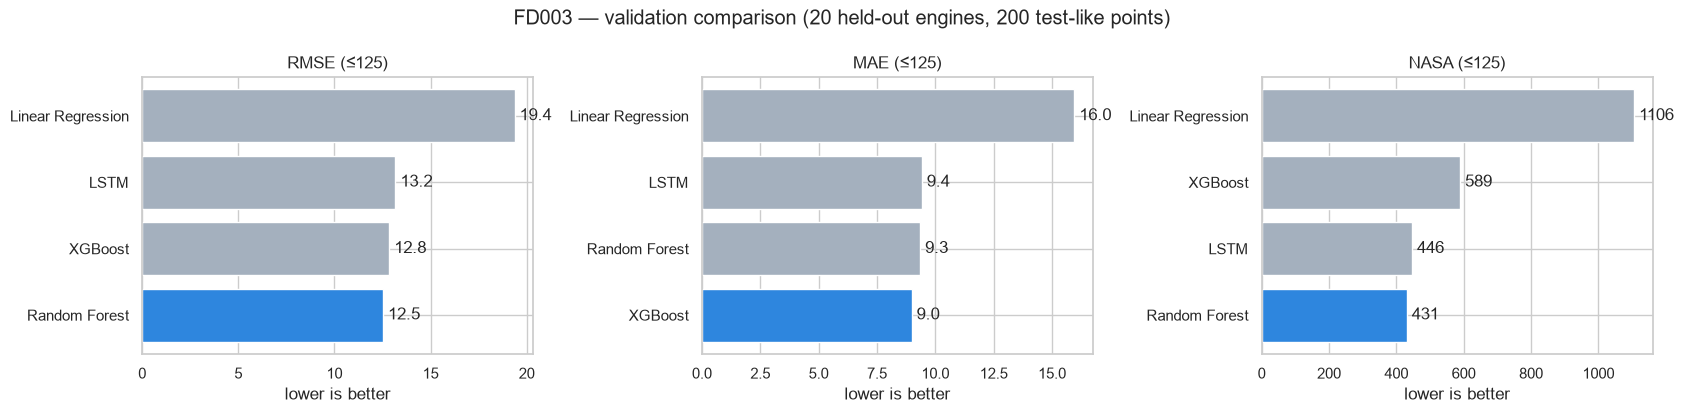

Current leader on the primary metric: Random Forest
Formal selection + the official test evaluation happen in Phase 6.


In [9]:
# Cell 9 — Comparison table + chart
cols = {"MAE_le_cap": f"MAE (≤{CAP})", "RMSE_le_cap": f"RMSE (≤{CAP})", "NASA_le_cap": f"NASA (≤{CAP})",
        "bias_le_cap": f"Bias (≤{CAP})", "RMSE_all": "RMSE (all points)", "train_s": "Train time (s)",
        "tuning_s": "Tuning time (s)", "infer_ms": "Inference (ms, all val points)"}
comparison = pd.DataFrame(results).T[list(cols)].rename(columns=cols)
comparison.index.name = "Model"
comparison.to_csv(RESULT_DIR / "validation_comparison.csv")
pd.DataFrame(val_preds).to_csv(RESULT_DIR / "validation_predictions.csv", index=False)
display(comparison.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col in zip(axes, [f"RMSE (≤{CAP})", f"MAE (≤{CAP})", f"NASA (≤{CAP})"]):
    s = comparison[col].sort_values()
    ax.barh(s.index, s.values, color=["#2E86DE" if i == 0 else "#A4B0BE" for i in range(len(s))])
    for y_, v in enumerate(s.values):
        ax.text(v, y_, f" {v:.1f}" if "NASA" not in col else f" {v:.0f}", va="center")
    ax.set(title=col, xlabel="lower is better")
fig.suptitle(f"{FD} — validation comparison ({len(val_ids)} held-out engines, {N_VAL} test-like points)")
fig.tight_layout(); fig.savefig(FIG_DIR / "train_validation_comparison.png", dpi=150, bbox_inches="tight"); plt.show()
print("Current leader on the primary metric:", comparison[f"RMSE (≤{CAP})"].idxmin())
print("Formal selection + the official test evaluation happen in Phase 6.")

In [10]:
# Cell 10 — Artifact inventory
for sub in ["preprocessing", "linear_regression", "random_forest", "xgboost", "lstm"]:
    files = sorted((MODEL_DIR / sub).iterdir())
    print(f"{sub + '/':20s}", ", ".join(f"{f.name} ({f.stat().st_size / 1e6:.2f} MB)" for f in files))

preprocessing/       pipeline_metadata.json (0.00 MB), preprocessing_config.json (0.00 MB), scaler.joblib (0.00 MB)
linear_regression/   metadata.json (0.00 MB), model.joblib (0.00 MB)
random_forest/       metadata.json (0.00 MB), model.joblib (11.72 MB)
xgboost/             metadata.json (0.00 MB), model.json (0.80 MB)
lstm/                metadata.json (0.00 MB), model.pt (0.11 MB), tuning_best_checkpoint.pt (0.11 MB)


## Reference results (full local CPU run of this notebook)
Linear Regression and Random Forest should match closely. XGBoost and the LSTM trained on a GPU will differ a little (typically ±1 RMSE), and the LSTM may choose a different architecture or epoch count.

| Model | MAE (≤cap) | RMSE (≤cap) | NASA (≤cap) | Bias | RMSE (all) | Chosen hyperparameters |
|---|---:|---:|---:|---:|---:|---|
| Linear Regression | 15.95 | 19.37 | 1106 | +7.2 | 53.23 | — |
| Random Forest | 9.35 | 12.52 | 431 | +6.5 | 49.68 | leaf 3, max_features 0.33, 150 trees |
| XGBoost | 8.98 | 12.85 | 589 | +6.0 | 49.67 | depth 3, lr 0.03, 667 trees |
| LSTM | 9.42 | 13.17 | 446 | +4.8 | 50.64 | 64 hidden, 1 layer(s), 8 epochs, input 30×28 |

**Note on the LSTM:** early stopping chose epoch 7–8 across the four architectures. The tune-engine loss stops improving after only a few epochs, which is a sign of quick overfitting, so the LSTM is expected to trail the tree models on this dataset.

## ✅ Verify before Phase 6
1. Cell 2 prints the expected preprocessor, feature count and shapes.
2. Each model cell prints a validation line and `saved … MB`; Cell 8 prints `✅ LSTM saved + reload verified`.
3. Cell 9 lists all 4 models.

**Next:** `10b_Evaluation_FD003`: select the FD003 model (validation only), then evaluate it **once** on the official test set.